# Employee attrition: can a neural network beat simple models?

**Goal:** predict which employees are likely to leave, so that HR can talk to them first, and find out whether a **PyTorch neural network** adds anything over simpler models.

**Data:** the *IBM HR Analytics Employee Attrition & Performance* dataset: 1,470 employees, 35 columns, 237 of whom left (16.1%). **It is a fictional dataset created by IBM data scientists**, so the results show how the methods behave, not what real employees do. Put `HR_Employee_Attrition_Data.csv` in a `data/` folder next to this notebook.

**The trap to avoid:** only 16% of employees leave, so a model that always answers "stays" is already 84% accurate. Accuracy cannot tell a useful model from a useless one here.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn, optim
import torch.utils.data as Data
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, OneHotEncoder, StandardScaler

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); torch.set_num_threads(2)
sns.set_theme(style="whitegrid")

## 1. The data

In [2]:
raw = pd.read_csv("data/HR_Employee_Attrition_Data.csv")
print("Rows, columns:", raw.shape, "| missing values:", int(raw.isna().sum().sum()), "| duplicated rows:", int(raw.drop(columns="EmployeeNumber").duplicated().sum()))
print("Columns with a single value:", [c for c in raw.columns if raw[c].nunique() == 1], "| employee id column: EmployeeNumber")
print(f"Left the company: {(raw.Attrition == 'Yes').sum()} of {len(raw)} ({(raw.Attrition == 'Yes').mean():.1%}) -> always answering 'stays' is {(raw.Attrition == 'No').mean():.1%} accurate")
data = raw.drop(columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"])   # constant columns and an id carry no information
y = (data.Attrition == "Yes").astype(int).values
X = data.drop(columns="Attrition")
categorical = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
numeric = [c for c in X.columns if c not in categorical]
print(f"\nInputs: {len(numeric)} numeric and {len(categorical)} categorical columns -> {categorical}")

Rows, columns: (1470, 35) | missing values: 0 | duplicated rows: 0
Columns with a single value: ['EmployeeCount', 'Over18', 'StandardHours'] | employee id column: EmployeeNumber
Left the company: 237 of 1470 (16.1%) -> always answering 'stays' is 83.9% accurate

Inputs: 23 numeric and 7 categorical columns -> ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


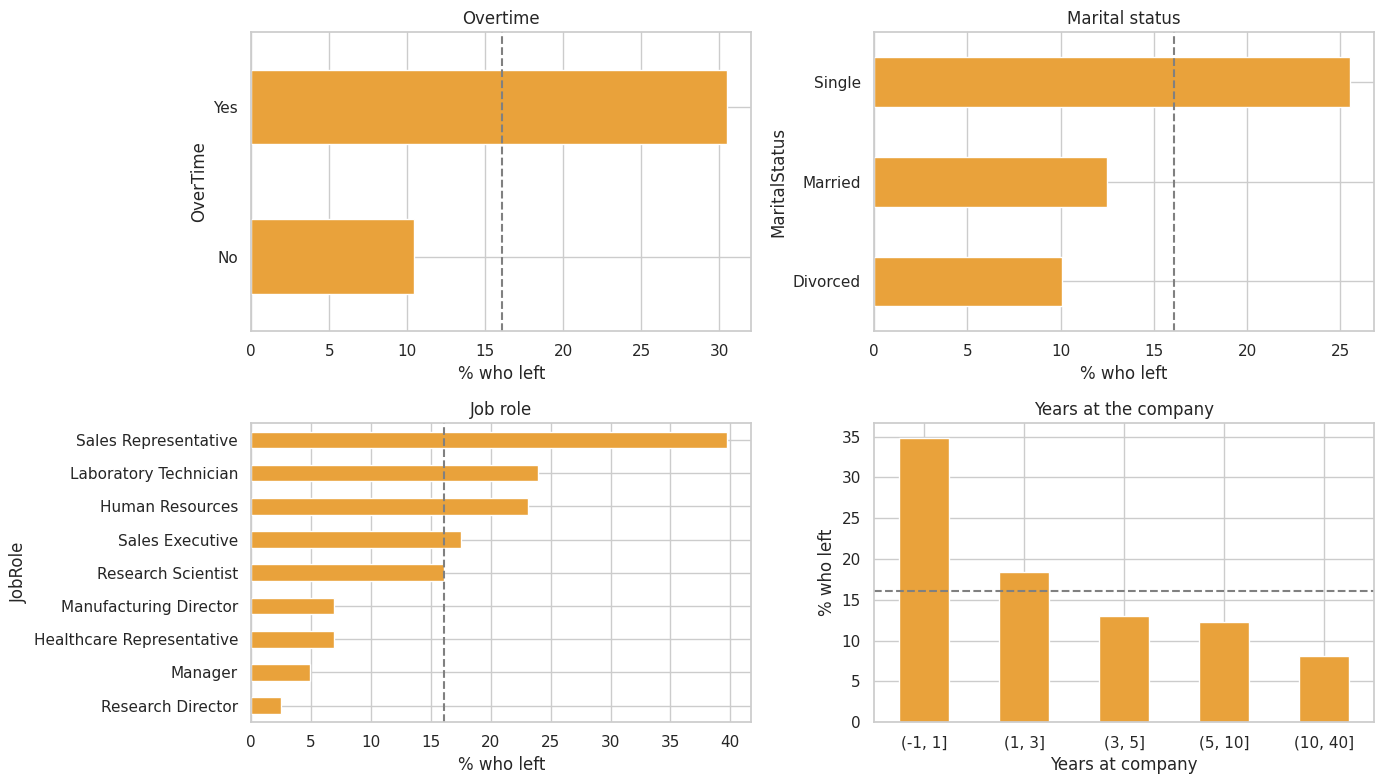

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
def rate(col, ax, title, order=None):
    r = data.groupby(col).Attrition.apply(lambda s: (s == "Yes").mean() * 100)
    r = r.reindex(order) if order is not None else r.sort_values()
    r.plot.barh(ax=ax, color="#e9a23b"); ax.set_title(title); ax.set_xlabel("% who left"); ax.axvline(16.1, color="grey", ls="--")
rate("OverTime", axes[0, 0], "Overtime"); rate("MaritalStatus", axes[0, 1], "Marital status"); rate("JobRole", axes[1, 0], "Job role")
data.assign(**{"Years at company": pd.cut(data.YearsAtCompany, [-1, 1, 3, 5, 10, 40])}).groupby("Years at company").Attrition.apply(lambda s: (s == "Yes").mean() * 100).plot.bar(ax=axes[1, 1], color="#e9a23b", rot=0)
axes[1, 1].set_title("Years at the company"); axes[1, 1].set_ylabel("% who left"); axes[1, 1].axhline(16.1, color="grey", ls="--")
plt.tight_layout(); plt.show()

## 2. What the first version really did

The first version of this project preprocessed the **whole** dataset (outlier capping, min-max scaling, label encoding), split at random and trained a `Softmax` network with `NLLLoss` and SGD, reporting only the accuracy. This is that recipe, re-created (the integer codes of `BusinessTravel` and `Department` are my reconstruction; the rest follows its code):

In [4]:
def first_version_recipe(seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    df1 = raw.copy()
    num = [c for c in raw.columns if pd.api.types.is_numeric_dtype(raw[c])]
    q1, q3 = df1[num].quantile(.25), df1[num].quantile(.75); iqr = q3 - q1; up, lo = q3 + 1.5 * iqr, q1 - 1.5 * iqr
    df1[num] = np.where(df1[num] > up, up, np.where(df1[num] < lo, lo, df1[num]))          # outlier capping on ALL the data
    df1[num] = MinMaxScaler().fit_transform(df1[num])                                       # scaling on ALL the data
    for c in ["OverTime", "Gender", "Over18", "MaritalStatus", "Attrition", "Department"]:
        df1[c] = LabelEncoder().fit_transform(df1[c])
    df1["BusinessTravel"] = raw["BusinessTravel"].map({"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2})
    df1 = pd.get_dummies(df1, columns=["EducationField", "JobRole"], drop_first=True).astype(float)
    A, t = df1.drop("Attrition", axis=1), df1["Attrition"].values
    Xa, Xb, ya, yb = train_test_split(A.values, t, test_size=0.2, random_state=42)           # random split, not stratified
    Xa, ya = torch.tensor(Xa, dtype=torch.float32), torch.tensor(ya, dtype=torch.float32)
    model = nn.Sequential(nn.Linear(A.shape[1], 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 2), nn.Softmax(dim=1))
    crit, opt = nn.NLLLoss(), optim.SGD(model.parameters(), lr=0.01)
    loader = Data.DataLoader(Data.TensorDataset(Xa, ya), batch_size=64, shuffle=True)
    for _ in range(100):
        for bx, by in loader:
            opt.zero_grad(); crit(model(bx), by.long()).backward(); opt.step()
    with torch.no_grad():
        p = model(torch.tensor(Xb, dtype=torch.float32))
    return yb, p.argmax(1).numpy(), p[:, 1].numpy()

yb, pred, prob = first_version_recipe()
print(f"Test employees: {len(yb)} | who left: {int(yb.sum())}")
print(f"Accuracy of the first version's recipe:        {accuracy_score(yb, pred):.3f}")
print(f"Accuracy of always answering 'stays':           {1 - yb.mean():.3f}")
print(f"Employees the network flags as leavers:         {int(pred.sum())}   (recall of the leavers: {recall_score(yb, pred):.0%})")
print(f"ROC-AUC of its probabilities:                   {roc_auc_score(yb, prob):.3f}   (0.5 = no better than a coin)")

Test employees: 294 | who left: 39
Accuracy of the first version's recipe:        0.867
Accuracy of always answering 'stays':           0.867
Employees the network flags as leavers:         0   (recall of the leavers: 0%)
ROC-AUC of its probabilities:                   0.559   (0.5 = no better than a coin)


The network reaches exactly the accuracy of answering "stays" because **it flags nobody**: it has collapsed to the majority class. Two things caused it: a `Softmax` followed by `NLLLoss` (which expects *log*-probabilities, so the training signal is weak) and a metric, accuracy, that rewards doing nothing.

## 3. How to evaluate this properly

- A **stratified** 80/20 split first, so both sets keep the 16% of leavers. The test set (294 employees, 47 leavers) is touched **once, at the end**.
- Model selection by **repeated stratified 5-fold cross-validation on the training set** (2 repeats, 10 folds). Scaling and encoding are fitted inside each fold.
- Metrics that suit a rare outcome: **ROC-AUC**, **PR-AUC** (average precision; a random guess scores the 16% prevalence) and a practical one, **recall in the top 20%**: *if HR can talk to the 20% of employees with the highest predicted risk, what share of the leavers is among them?* A random pick would catch 20%.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Train: {len(X_train)} employees, {y_train.sum()} leavers ({y_train.mean():.1%}) | Test: {len(X_test)} employees, {y_test.sum()} leavers ({y_test.mean():.1%})")

def preprocessor():
    return ColumnTransformer([("num", StandardScaler(), numeric), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)])

def recall_at(y_true, score, frac=0.20):
    k = int(round(len(y_true) * frac)); top = np.argsort(-score, kind="stable")[:k]
    return y_true[top].sum() / y_true.sum()

def metrics(y_true, score):
    return {"ROC-AUC": roc_auc_score(y_true, score), "PR-AUC": average_precision_score(y_true, score), "recall in top 20%": recall_at(y_true, score)}

Train: 1176 employees, 190 leavers (16.2%) | Test: 294 employees, 47 leavers (16.0%)


## 4. The PyTorch network

A small feed-forward network (two hidden layers of 32 and 16 units, ReLU, dropout 0.3). What changes from the first version: the output is a **single logit trained with `BCEWithLogitsLoss`** (no `Softmax` + `NLLLoss` mismatch), the loss gives **more weight to the rare class** (`pos_weight`), the optimiser is Adam with weight decay, and **early stopping** on a validation split taken from the training data decides when to stop.

In [6]:
class AttritionNet:
    def __init__(self, hidden=(32, 16), dropout=0.3, weight_decay=1e-3, lr=1e-3, max_epochs=300, patience=20, batch_size=64, seed=SEED):
        self.hidden, self.dropout, self.weight_decay, self.lr = hidden, dropout, weight_decay, lr
        self.max_epochs, self.patience, self.batch_size, self.seed = max_epochs, patience, batch_size, seed

    def fit(self, A, t):
        torch.manual_seed(self.seed)
        tr, va = train_test_split(np.arange(len(t)), test_size=0.15, stratify=t, random_state=self.seed)       # validation split for early stopping
        At, tt, Av, tv = (torch.tensor(a, dtype=torch.float32) for a in (A[tr], t[tr], A[va], t[va]))
        layers, n = [], A.shape[1]
        for h in self.hidden:
            layers += [nn.Linear(n, h), nn.ReLU(), nn.Dropout(self.dropout)]; n = h
        self.net = nn.Sequential(*layers, nn.Linear(n, 1))
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((tt == 0).sum() / max((tt == 1).sum(), 1), dtype=torch.float32))
        opt = optim.Adam(self.net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        best, wait, state, self.history = 1e9, 0, None, []
        for epoch in range(self.max_epochs):
            self.net.train(); order = torch.randperm(len(tt)); running = 0.0
            for i in range(0, len(order), self.batch_size):
                b = order[i:i + self.batch_size]; opt.zero_grad()
                loss = loss_fn(self.net(At[b]).squeeze(1), tt[b]); loss.backward(); opt.step(); running += loss.item() * len(b)
            self.net.eval()
            with torch.no_grad():
                val = loss_fn(self.net(Av).squeeze(1), tv).item()
            self.history.append((running / len(tt), val))
            if val < best - 1e-4:
                best, wait, state = val, 0, {k: v.clone() for k, v in self.net.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.net.load_state_dict(state); self.epochs_run = epoch + 1
        return self

    def score(self, A):
        self.net.eval()
        with torch.no_grad():
            return self.net(torch.tensor(A, dtype=torch.float32)).squeeze(1).numpy()

## 5. Model comparison by cross-validation (training set only)

Prevalence of leavers: 0.162 (PR-AUC of a random guess) | the network stopped after a median of 41 epochs


,ROC-AUC,ROC-AUC std,PR-AUC,recall in top 20%
model,,,,
logistic regression,0.832,0.031,0.629,0.645
neural network (PyTorch),0.826,0.037,0.642,0.642
gradient boosting,0.818,0.030,0.609,0.600
random forest,0.805,0.033,0.562,0.582
rule: works overtime,0.622,0.046,0.249,0.342
always stays,0.500,0.000,0.162,0.187


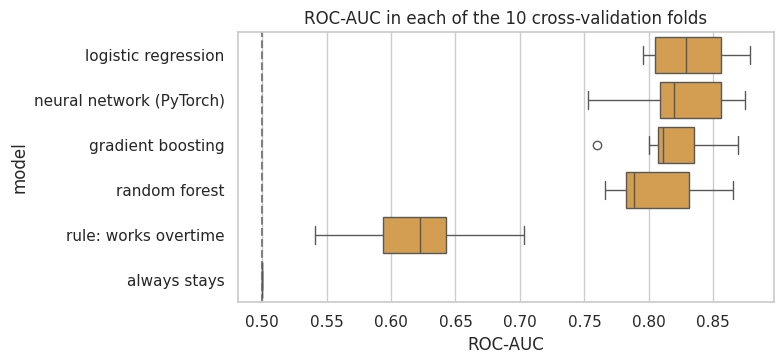

In [7]:
MODELS = {
    "always stays":                lambda: DummyClassifier(strategy="prior"),
    "logistic regression":         lambda: LogisticRegression(max_iter=3000, class_weight="balanced", C=0.1),
    "random forest":               lambda: RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "gradient boosting":           lambda: GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
rows, epochs = [], []
for fold, (a, b) in enumerate(cv.split(X_train, y_train)):
    prep = preprocessor().fit(X_train.iloc[a]); A, B = prep.transform(X_train.iloc[a]), prep.transform(X_train.iloc[b]); ya, yb = y_train[a], y_train[b]
    for name, make in MODELS.items():
        score = make().fit(A, ya).predict_proba(B)[:, 1]; rows.append({"fold": fold, "model": name, **metrics(yb, score)})
    rule = (X_train.iloc[b].OverTime == "Yes").astype(float).values                          # one-feature rule: "works overtime"
    rows.append({"fold": fold, "model": "rule: works overtime", **metrics(yb, rule + np.random.RandomState(0).rand(len(rule)) * 1e-3)})
    net = AttritionNet().fit(A, ya); epochs.append(net.epochs_run); rows.append({"fold": fold, "model": "neural network (PyTorch)", **metrics(yb, net.score(B))})
cvres = pd.DataFrame(rows)
summary = cvres.groupby("model").agg(**{"ROC-AUC": ("ROC-AUC", "mean"), "ROC-AUC std": ("ROC-AUC", "std"), "PR-AUC": ("PR-AUC", "mean"), "recall in top 20%": ("recall in top 20%", "mean")}).sort_values("ROC-AUC", ascending=False)
print(f"Prevalence of leavers: {y_train.mean():.3f} (PR-AUC of a random guess) | the network stopped after a median of {int(np.median(epochs))} epochs")
display(summary.round(3))
order = summary.index[::-1]
fig, ax = plt.subplots(figsize=(8, 3.8)); sns.boxplot(data=cvres, y="model", x="ROC-AUC", order=order[::-1], ax=ax, color="#e9a23b"); ax.axvline(0.5, color="grey", ls="--")
ax.set_title("ROC-AUC in each of the 10 cross-validation folds"); plt.tight_layout(); plt.show()

- The **PyTorch network and the logistic regression are indistinguishable**: the difference between them is far smaller than the spread between folds. The tree-based models are slightly behind.
- Every model is far above the one-feature rule and the baseline. Among the 20% of employees ranked highest, the best models find about **64% of the leavers** in cross-validation, against 20% for a random pick.

## 6. What the network learns

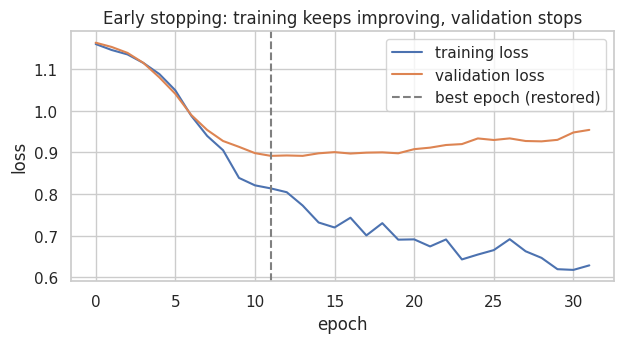

In [8]:
net = AttritionNet().fit(preprocessor().fit_transform(X_train), y_train)
hist = np.array(net.history)
fig, ax = plt.subplots(figsize=(6.4, 3.6)); ax.plot(hist[:, 0], label="training loss"); ax.plot(hist[:, 1], label="validation loss")
ax.axvline(net.epochs_run - 21, color="grey", ls="--", label="best epoch (restored)"); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend(); ax.set_title("Early stopping: training keeps improving, validation stops")
plt.tight_layout(); plt.show()

## 7. The final test: employees the models have never seen

Everything is fitted on the training set; the 294 test employees (47 leavers) are used **once**. With so few leavers, a single number is fragile, so the ROC-AUC comes with a bootstrap 95% interval.

In [9]:
prep = preprocessor().fit(X_train); A_tr, A_te = prep.transform(X_train), prep.transform(X_test)
scores = {name: make().fit(A_tr, y_train).predict_proba(A_te)[:, 1] for name, make in MODELS.items() if name != "always stays"}
scores["neural network (PyTorch)"] = AttritionNet().fit(A_tr, y_train).score(A_te)
rng = np.random.RandomState(SEED); n = len(y_test); boot = {k: [] for k in scores}; diff = []
for _ in range(1000):
    i = rng.randint(0, n, n)
    if y_test[i].sum() in (0, n): continue
    for k, s in scores.items(): boot[k].append(roc_auc_score(y_test[i], s[i]))
    diff.append(boot["neural network (PyTorch)"][-1] - boot["logistic regression"][-1])
test = pd.DataFrame({k: {**metrics(y_test, s), "ROC-AUC 95% interval": f"{np.percentile(boot[k], 2.5):.2f} - {np.percentile(boot[k], 97.5):.2f}"} for k, s in scores.items()}).T
display(test.assign(**{c: test[c].astype(float).round(3) for c in ["ROC-AUC", "PR-AUC", "recall in top 20%"]}).sort_values("ROC-AUC", ascending=False))
lo, hi = np.percentile(diff, [2.5, 97.5]); print(f"Network minus logistic regression, ROC-AUC difference: {np.mean(diff):+.3f}   95% interval [{lo:+.3f}, {hi:+.3f}]  -> {'includes zero: no real difference' if lo < 0 < hi else 'excludes zero'}")

,ROC-AUC,PR-AUC,recall in top 20%,ROC-AUC 95% interval
logistic regression,0.812,0.588,0.574,0.74 - 0.88
gradient boosting,0.806,0.493,0.553,0.73 - 0.87
neural network (PyTorch),0.788,0.548,0.574,0.70 - 0.86
random forest,0.787,0.439,0.574,0.71 - 0.86


Network minus logistic regression, ROC-AUC difference: -0.024   95% interval [-0.055, +0.006]  -> includes zero: no real difference


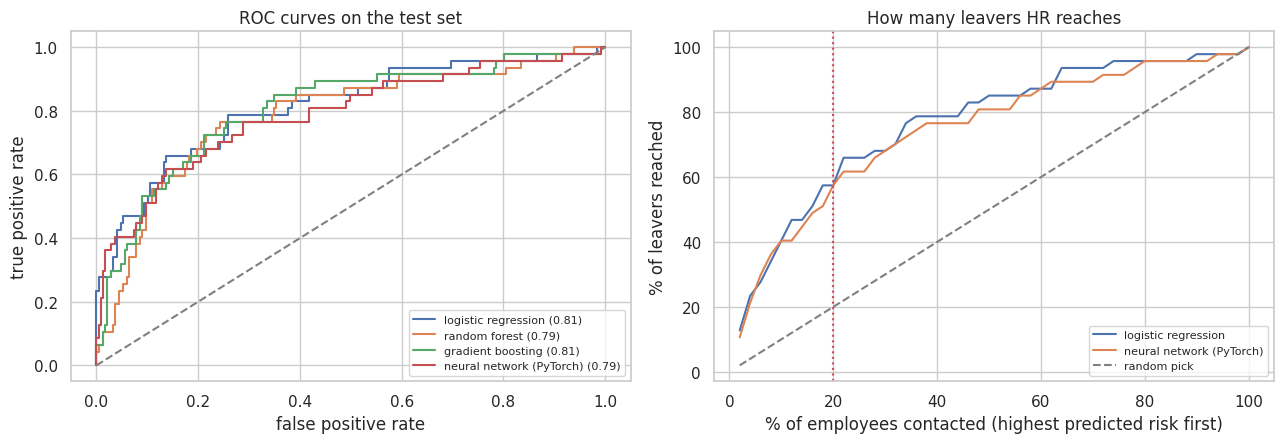

Contacting the 59 highest-risk employees (20%): the network reaches 27 of the 47 leavers (57%); a random pick would reach about 9.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s); axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, s):.2f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].set_title("ROC curves on the test set"); axes[0].legend(fontsize=8)
fracs = np.linspace(0.02, 1, 50)
for name in ("logistic regression", "neural network (PyTorch)"):
    axes[1].plot(fracs * 100, [recall_at(y_test, scores[name], f) * 100 for f in fracs], label=name)
axes[1].plot(fracs * 100, fracs * 100, "--", color="grey", label="random pick"); axes[1].axvline(20, color="#d1495b", ls=":")
axes[1].set_xlabel("% of employees contacted (highest predicted risk first)"); axes[1].set_ylabel("% of leavers reached"); axes[1].set_title("How many leavers HR reaches"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
k = int(round(len(y_test) * 0.20)); top = np.argsort(-scores["neural network (PyTorch)"], kind="stable")[:k]
print(f"Contacting the {k} highest-risk employees (20%): the network reaches {y_test[top].sum()} of the {y_test.sum()} leavers ({y_test[top].sum() / y_test.sum():.0%}); a random pick would reach about {y_test.sum() * 0.2:.0f}.")

## 8. What drives attrition? (logistic regression coefficients)

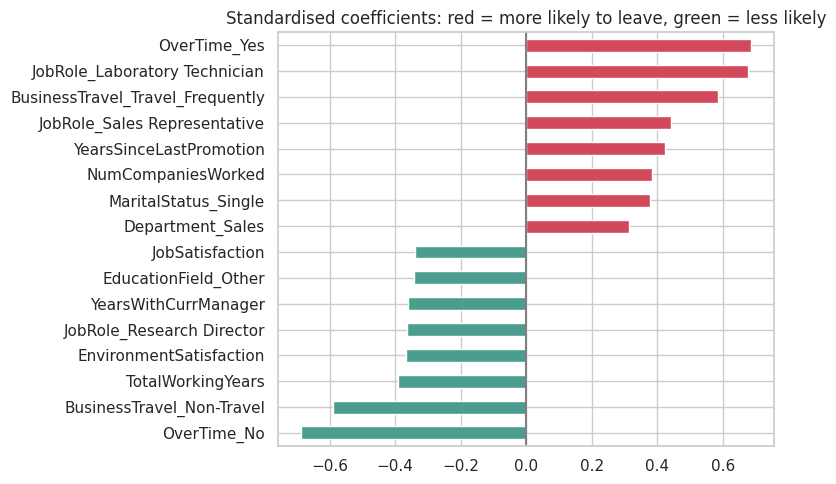

Pushes toward leaving : OverTime_Yes, JobRole_Laboratory Technician, BusinessTravel_Travel_Frequently, JobRole_Sales Representative, YearsSinceLastPromotion, NumCompaniesWorked
Pushes toward staying : OverTime_No, BusinessTravel_Non-Travel, TotalWorkingYears, EnvironmentSatisfaction, JobRole_Research Director, YearsWithCurrManager


In [11]:
lr = LogisticRegression(max_iter=3000, class_weight="balanced", C=0.1).fit(A_tr, y_train)
names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
coef = pd.Series(lr.coef_[0], index=names).sort_values()
show = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(8, 5)); show.plot.barh(ax=ax, color=["#4a9d8f" if v < 0 else "#d1495b" for v in show]); ax.axvline(0, color="grey")
ax.set_title("Standardised coefficients: red = more likely to leave, green = less likely"); plt.tight_layout(); plt.show()
print("Pushes toward leaving :", ", ".join(coef.tail(6)[::-1].index)); print("Pushes toward staying :", ", ".join(coef.head(6).index))

## 9. Conclusions

- **The accuracy hid a collapsed model.** The first version's recipe scores 86.7%, exactly what answering "stays" gives, because it flags **nobody** (recall of the leavers 0%, ROC-AUC 0.56). Causes: a `Softmax` followed by `NLLLoss`, a metric that rewards doing nothing, and preprocessing the whole dataset before splitting.
- **Evaluated properly, simple models do as well as the network.** In cross-validation the ROC-AUC is 0.832 for the logistic regression, 0.826 for the PyTorch network, 0.818 for gradient boosting and 0.805 for the random forest, all far above the "works overtime" rule (0.62) and the baseline (0.50).
- **The neural network adds nothing here.** On the test set it is at 0.788 against 0.812 for the logistic regression, but the paired bootstrap difference (-0.024, interval -0.055 to +0.006) includes zero. With 1,470 employees and 30 inputs, a logistic regression is as good, faster and easier to explain.
- **The practical value is real:** contacting the 20% of employees with the highest predicted risk reaches **57% of the leavers on the test set** (27 of 47), against about 9 for a random pick, and about 64% in cross-validation.
- **What goes with leaving:** overtime, frequent business travel, the laboratory-technician and sales-representative roles, more companies worked for and more time since the last promotion. **What goes with staying:** no business travel, more years of total experience, satisfaction with the environment and more years with the current manager.

**Limitations**

- This is a **fictional dataset** created by IBM data scientists, so the findings describe the methods, not real employees.
- These are associations, not causes, and a model like this should prioritise supportive conversations, never penalise people.
- The test set has only 47 leavers, so the intervals are wide (for example 0.70 to 0.86 for the network).
- The network was not tuned beyond a sensible default, and the re-creation of the first version includes my own reconstruction of two columns' encoding.

**Next steps:** tune and calibrate the models, check that the errors are similar across groups of employees, and repeat the evaluation on real data.